# Lab 8 - Edge Detection

**Name** Mujtaba Alnuwaysir 
**ID** 2240007941
**Class** 7MA2

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# A new image (NOT the notebook's original 'kid1.jpg')
imgFile = 'Home.png'

img = cv2.imread(imgFile)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
print('Image shape:', img.shape)

Image shape: (148, 202, 3)


## Task 1: Apply Edge Detection Methods

### Sobel Edge Detector

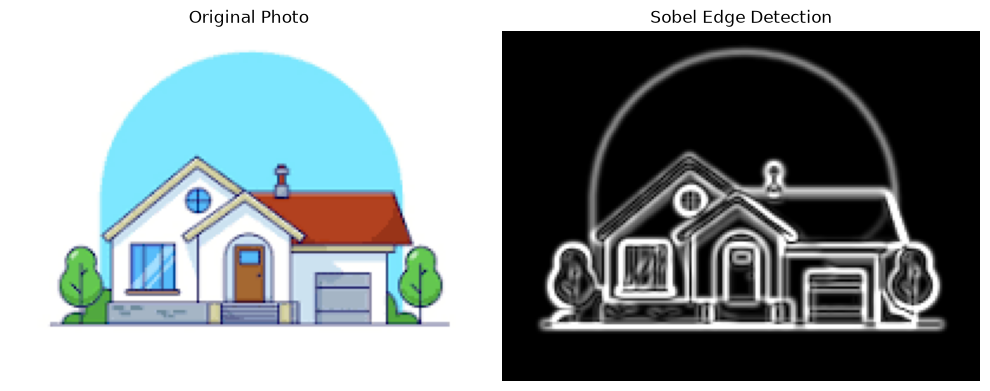

In [4]:
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined = cv2.magnitude(sobelx, sobely)
sobel_final = np.uint8(np.clip(sobel_combined, 0, 255))

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Photo'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(sobel_final, cmap='gray'), plt.title('Sobel Edge Detection'), plt.axis('off')
plt.tight_layout()
plt.show()

### Prewitt Edge Detector

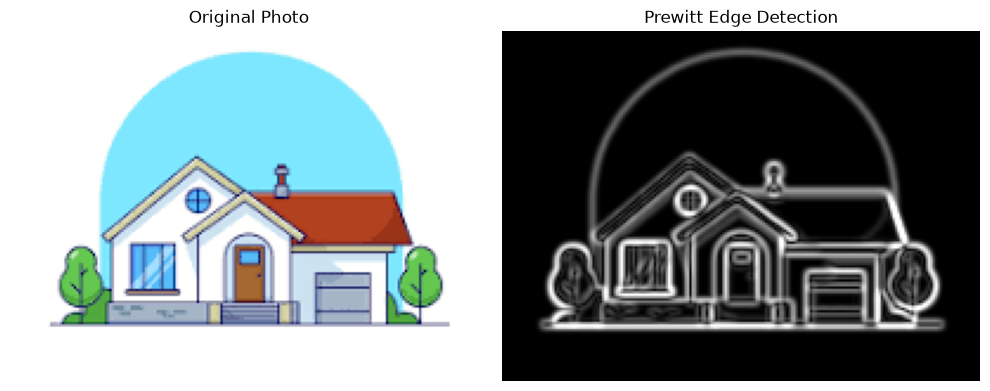

In [5]:
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)

prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)
prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_final = np.uint8(np.clip(prewitt_combined, 0, 255))

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Photo'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(prewitt_final, cmap='gray'), plt.title('Prewitt Edge Detection'), plt.axis('off')
plt.tight_layout()
plt.show()

### Canny Edge Detector

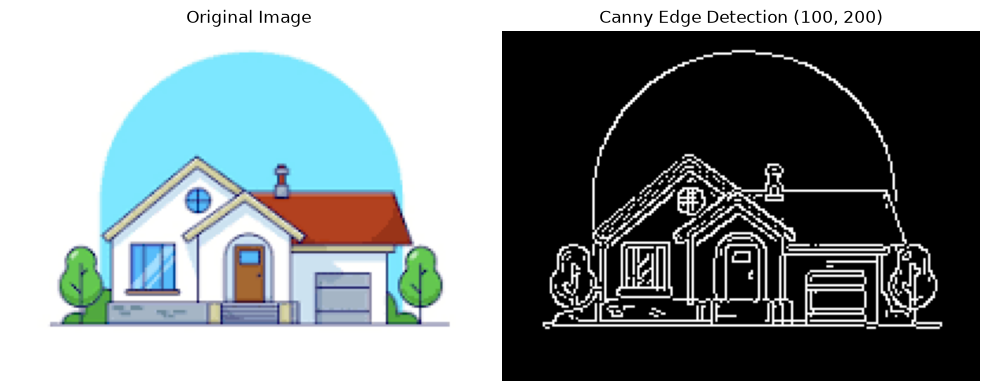

In [6]:
canny_edges = cv2.Canny(gray, 100, 200)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Image'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(canny_edges, cmap='gray'), plt.title('Canny Edge Detection (100, 200)'), plt.axis('off')
plt.tight_layout()
plt.show()

### Original image and the three edge maps together

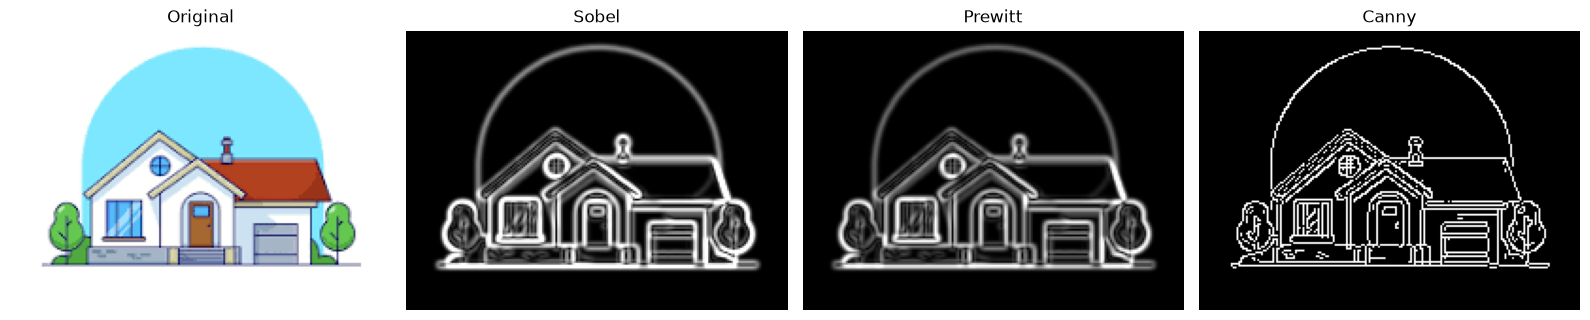

In [7]:
plt.figure(figsize=(16, 4.5))
plt.subplot(1, 4, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original'), plt.axis('off')
plt.subplot(1, 4, 2), plt.imshow(sobel_final, cmap='gray'), plt.title('Sobel'), plt.axis('off')
plt.subplot(1, 4, 3), plt.imshow(prewitt_final, cmap='gray'), plt.title('Prewitt'), plt.axis('off')
plt.subplot(1, 4, 4), plt.imshow(canny_edges, cmap='gray'), plt.title('Canny'), plt.axis('off')
plt.tight_layout()
plt.show()

**Observation:** Sobel and Prewitt are gradient-magnitude methods, so their results are grayscale maps with thick, soft edges where brighter pixels mean stronger edges. They look very similar because both use 3x3 kernels (Sobel gives extra weight to the centre row/column, so it is slightly smoother). Canny produces a clean binary map with thin, one-pixel-wide edges, because it adds non-maximum suppression and hysteresis thresholding on top of the gradient.

## Task 2: Investigate the Effect of Canny Thresholds

Low=30, High=90: edge pixels = 2909
Low=50, High=150: edge pixels = 2838
Low=100, High=200: edge pixels = 2739


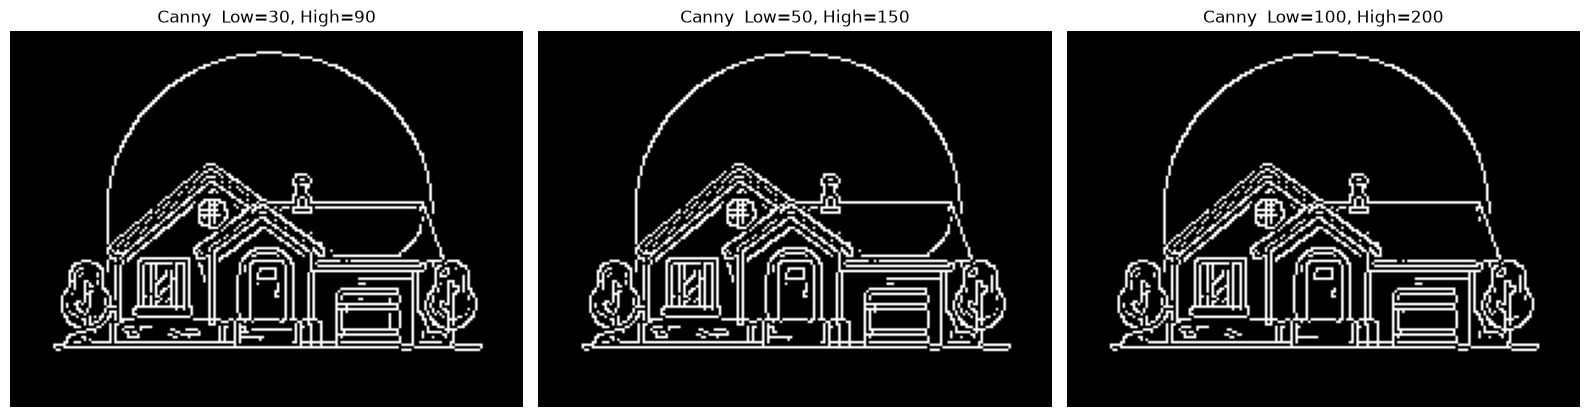

In [8]:
threshold_pairs = [(30, 90), (50, 150), (100, 200)]

plt.figure(figsize=(16, 5.5))
for i, (low, high) in enumerate(threshold_pairs, start=1):
    edges = cv2.Canny(gray, low, high)
    print(f'Low={low}, High={high}: edge pixels = {np.count_nonzero(edges)}')
    plt.subplot(1, 3, i)
    plt.imshow(edges, cmap='gray')
    plt.title(f'Canny  Low={low}, High={high}')
    plt.axis('off')
plt.tight_layout()
plt.show()

### Explanation

Canny keeps edges stronger than the high threshold, drops edges weaker than the low threshold, and keeps the ones in between only if they connect to a strong edge.

- **30 / 90:** Most edges and the most detail, but also a lot of noise.
- **50 / 150:** A good balance of detail and clean edges.
- **100 / 200:** Fewest edges. It looks clean, but small details are lost.

**Conclusion:** Higher thresholds give fewer edges and less detail. Lower thresholds give more detail but more noise.